In [10]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# ============================================================
# 1. Synthetic data generator — with random phase + noise
# ============================================================
def generate_trajectory(t, noise_std=0.02):
    """Generates a 2D wiggly trajectory with random phase shifts and Gaussian noise."""
    phase_x = np.random.uniform(0, 2 * np.pi)
    phase_y = np.random.uniform(0, 2 * np.pi)

    x = np.sin(2 * np.pi * t + phase_x) + 0.3 * np.sin(6 * np.pi * t + phase_y)
    y = np.cos(2 * np.pi * t + phase_y) + 0.3 * np.sin(4 * np.pi * t + 0.5 + phase_x)

    x += np.random.normal(0, noise_std, size=len(t))
    y += np.random.normal(0, noise_std, size=len(t))
    return np.stack([x, y], axis=1)


def create_dataset(num_samples=1000, seq_len=200, mask_frac=0.2):
    """Creates dataset of synthetic trajectories with random masking."""
    t = np.linspace(0, 1, seq_len)
    data, masks = [], []

    for _ in range(num_samples):
        traj = generate_trajectory(t)
        mask = np.zeros(seq_len)
        gap_len = int(mask_frac * seq_len)
        start = np.random.randint(0, seq_len - gap_len)
        mask[start:start + gap_len] = 1.0
        data.append(traj)
        masks.append(mask)

    return np.stack(data), np.stack(masks), t


# ============================================================
# 2. Temporal Convolutional Network
# ============================================================
class TCNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=5, dilation=1):
        super().__init__()
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size,
                              padding=(kernel_size - 1) * dilation // 2,
                              dilation=dilation)
        self.ln = nn.LayerNorm(out_channels)
        self.act = nn.ReLU()
        self.res = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        out = self.conv(x)
        out = out.transpose(1, 2)
        out = self.ln(out)
        out = out.transpose(1, 2)
        out = self.act(out)
        return out + self.res(x)


class TCN(nn.Module):
    def __init__(self, in_channels=4, hidden_dim=64, num_layers=5, kernel_size=5):
        super().__init__()
        layers = []
        for i in range(num_layers):
            dilation = 2 ** i
            layers.append(TCNBlock(in_channels if i == 0 else hidden_dim,
                                   hidden_dim,
                                   kernel_size=kernel_size,
                                   dilation=dilation))
        self.network = nn.Sequential(*layers)
        self.head = nn.Conv1d(hidden_dim, 2, kernel_size=1)

    def forward(self, x):
        x = x.permute(0, 2, 1)  # (B, 4, T)
        out = self.network(x)
        out = self.head(out)
        return out.permute(0, 2, 1)  # (B, T, 2)


# ============================================================
# 3. Training setup
# ============================================================
def validate_model(model, data, masks, t, alpha, lambda_cont, lambda_smooth, device="cpu"):
    model.eval()
    total_losses = []
    criterion = nn.MSELoss(reduction='none')

    with torch.no_grad():
        for i in range(len(data)):
            traj = torch.tensor(data[i], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[i], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)
            time = torch.tensor(t, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)

            inp = torch.cat([traj * (1 - mask), mask, time], dim=-1)
            pred = model(inp)

            # Weighted MSE loss
            mse_masked = criterion(pred, traj) * mask
            mse_unmasked = criterion(pred, traj) * (1 - mask)
            loss_mse = mse_masked.mean() + alpha * mse_unmasked.mean()

            # Continuity loss
            mask_diff = mask[:, 1:] - mask[:, :-1]
            start_idx = (mask_diff == 1).nonzero(as_tuple=True)
            end_idx = (mask_diff == -1).nonzero(as_tuple=True)

            loss_cont = 0.0
            if len(start_idx[0]) > 0:
                loss_cont += torch.mean((pred[start_idx[0], start_idx[1], :] -
                                         traj[start_idx[0], start_idx[1] - 1, :]) ** 2)
            if len(end_idx[0]) > 0:
                loss_cont += torch.mean((pred[end_idx[0], end_idx[1], :] -
                                         traj[end_idx[0], end_idx[1] + 1, :]) ** 2)

            # Smoothness loss
            loss_smooth = torch.mean((pred[:, 1:, :] - pred[:, :-1, :]) ** 2)

            total_loss = loss_mse + lambda_cont * loss_cont + lambda_smooth * loss_smooth
            total_losses.append(total_loss.item())

    if len(total_losses) > 0:
        return np.mean(total_losses)
    else:
        return 0.0 # Return 0.0 if no masked regions to avoid errors, or handle as NaN if preferred

def train_tcn(model, optimizer, data_train, masks_train, data_val, masks_val, t, epochs=100, alpha=0.1,
              lambda_cont=0.5, lambda_smooth=0.5, device="cpu"):

    model.train()
    criterion = nn.MSELoss(reduction='none')
    epoch_train_losses = []
    epoch_val_losses = []

    for epoch in range(epochs):
        perm = np.random.permutation(len(data_train))
        total_train_loss = 0

        for i in perm:
            traj = torch.tensor(data_train[i], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks_train[i], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)
            time = torch.tensor(t, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)

            inp = torch.cat([traj * (1 - mask), mask, time], dim=-1)
            pred = model(inp)

            # Weighted MSE loss
            mse_masked = criterion(pred, traj) * mask
            mse_unmasked = criterion(pred, traj) * (1 - mask)
            loss_mse = mse_masked.mean() + alpha * mse_unmasked.mean()

            # Continuity loss
            mask_diff = mask[:, 1:] - mask[:, :-1]
            start_idx = (mask_diff == 1).nonzero(as_tuple=True)
            end_idx = (mask_diff == -1).nonzero(as_tuple=True)

            loss_cont = 0.0
            if len(start_idx[0]) > 0:
                loss_cont += torch.mean((pred[start_idx[0], start_idx[1], :] -
                                         traj[start_idx[0], start_idx[1] - 1, :]) ** 2)
            if len(end_idx[0]) > 0:
                loss_cont += torch.mean((pred[end_idx[0], end_idx[1], :] -
                                         traj[end_idx[0], end_idx[1] + 1, :]) ** 2)

            # Smoothness loss
            loss_smooth = torch.mean((pred[:, 1:, :] - pred[:, :-1, :]) ** 2)

            loss = loss_mse + lambda_cont * loss_cont + lambda_smooth * loss_smooth

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()

        epoch_avg_train_loss = total_train_loss / len(data_train)
        epoch_train_losses.append(epoch_avg_train_loss)

        # Validation step
        val_loss = validate_model(model, data_val, masks_val, t, alpha, lambda_cont, lambda_smooth, device)
        epoch_val_losses.append(val_loss)

        print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {epoch_avg_train_loss:.6f} | Val Loss: {val_loss:.6f}")

    return epoch_train_losses, epoch_val_losses


# ============================================================
# 4. Quantitative evaluation
# ============================================================
def evaluate_model(model, data, masks, t, device="cpu"):
    model.eval()
    mse_list, mae_list, r2_list = [], [], []

    with torch.no_grad():
        for i in range(len(data)):
            traj = torch.tensor(data[i], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[i], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)
            time = torch.tensor(t, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)

            inp = torch.cat([traj * (1 - mask), mask, time], dim=-1)
            pred = model(inp).detach().cpu().numpy().squeeze(0)
            traj = traj.detach().cpu().numpy().squeeze(0)
            mask = mask.detach().cpu().numpy().squeeze(0).squeeze(-1)

            masked_idx = mask == 1
            if np.any(masked_idx):
                mse = mean_squared_error(traj[masked_idx], pred[masked_idx])
                mae = mean_absolute_error(traj[masked_idx], pred[masked_idx])
                r2 = r2_score(traj[masked_idx], pred[masked_idx])
                mse_list.append(mse)
                mae_list.append(mae)
                r2_list.append(r2)

    mse_mean, mse_std = np.mean(mse_list), np.std(mse_list)
    mae_mean, mae_std = np.mean(mae_list), np.std(mae_list)
    r2_mean, r2_std = np.mean(r2_list), np.std(r2_list)

    print(f"\nQuantitative Evaluation on Masked Regions:")
    print(f"Mean MSE: {mse_mean:.6f} \u00b1 {mse_std:.6f}")
    print(f"Mean MAE: {mae_mean:.6f} \u00b1 {mae_std:.6f}")
    print(f"Mean R\u00b2:  {r2_mean:.6f} \u00b1 {r2_std:.6f}")

    latex_table = f"""
\n\\begin{{table}}[t]
\\centering
\\caption{{Quantitative evaluation on masked regions ({len(data)} synthetic\n         trajectories, 20\\% mask fraction).}}
\\label{{tab:results_main}}
\\begin{{tabular}}{{ll}}
\\toprule
\\textbf{{Metric}} & \\textbf{{Mean $\\pm$ Std}} \\
\\midrule
MSE & ${mse_mean:.6f} \\pm {mse_std:.6f}$ \\
MAE & ${mae_mean:.6f} \\pm {mae_std:.6f}$ \\
R$^2$ & ${r2_mean:.6f} \\pm {r2_std:.6f}$ \\
\\bottomrule
\\end{{tabular}}
\\end{{table}}
"""
    print(latex_table)

    return mse_mean, mse_std, mae_mean, mae_std, r2_mean, r2_std


# ============================================================
# 5. Visualization
# ============================================================
def visualize_results(model, data, masks, t, num_examples=3, device="cpu"):
    model.eval()

    # ---- True vs Predicted ----
    fig, axes = plt.subplots(1, num_examples, figsize=(6 * num_examples, 5), dpi=120)
    if num_examples == 1:
        axes = [axes]

    with torch.no_grad():
        for i in range(num_examples):
            idx = np.random.randint(0, len(data))
            traj = torch.tensor(data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[idx], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)
            time = torch.tensor(t, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)

            inp = torch.cat([traj * (1 - mask), mask, time], dim=-1)
            pred = model(inp).detach().cpu().numpy().squeeze(0)
            traj = traj.detach().cpu().numpy().squeeze(0)
            mask = mask.detach().cpu().numpy().squeeze(0).squeeze(-1)

            axes[i].plot(traj[:, 0], traj[:, 1], color="gray", lw=2, label="True Trajectory")
            axes[i].plot(pred[:, 0], pred[:, 1], color="dodgerblue", lw=2, label="Predicted")
            masked = np.where(mask == 1)[0]
            if len(masked) > 0:
                axes[i].scatter(traj[masked, 0], traj[masked, 1], color="red", s=25, label="Masked region")

            axes[i].set_title(f"Example {i+1}", fontsize=13)
            axes[i].legend(frameon=False)
            axes[i].axis("equal")
            axes[i].grid(alpha=0.3)

    plt.suptitle("True vs Predicted Trajectories", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

    # ---- Reconstructed (input + predicted) ----
    fig, axes = plt.subplots(1, num_examples, figsize=(6 * num_examples, 5), dpi=120)
    if num_examples == 1:
        axes = [axes]

    for i in range(num_examples):
        idx = np.random.randint(0, len(data))
        traj = torch.tensor(data[idx], dtype=torch.float32, device=device).unsqueeze(0)
        mask = torch.tensor(masks[idx], dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)
        time = torch.tensor(t, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(-1)

        inp = torch.cat([traj * (1 - mask), mask, time], dim=-1)
        pred = model(inp).detach().cpu().numpy().squeeze(0)
        traj = traj.detach().cpu().numpy().squeeze(0)
        mask = mask.detach().cpu().numpy().squeeze(0).squeeze(-1)

        reconstructed = traj * (1 - mask[:, None]) + pred * mask[:, None]

        axes[i].plot(traj[:, 0], traj[:, 1], color="gray", lw=1.5, alpha=0.5, label="True")
        axes[i].plot(reconstructed[:, 0], reconstructed[:, 1], color="mediumseagreen", lw=2.5, label="Reconstructed (input + predicted)")
        axes[i].scatter(pred[mask == 1, 0], pred[mask == 1, 1], color="orange", s=25, label="Predicted (masked) points")

        axes[i].set_title(f"Reconstructed Trajectory (Example {i+1})", fontsize=13)
        axes[i].legend(frameon=False)
        axes[i].axis("equal")
        axes[i].grid(alpha=0.3)

    plt.suptitle("Reconstructed Trajectories (Input + Predicted)", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()



Using device: cuda
Epoch 1/50 | Train Loss: 0.159503 | Val Loss: 0.104060
Epoch 2/50 | Train Loss: 0.087857 | Val Loss: 0.045609
Epoch 3/50 | Train Loss: 0.031888 | Val Loss: 0.022748
Epoch 4/50 | Train Loss: 0.022492 | Val Loss: 0.019110
Epoch 5/50 | Train Loss: 0.016718 | Val Loss: 0.018143
Epoch 6/50 | Train Loss: 0.013891 | Val Loss: 0.012158
Epoch 7/50 | Train Loss: 0.012302 | Val Loss: 0.015007
Epoch 8/50 | Train Loss: 0.011411 | Val Loss: 0.009919
Epoch 9/50 | Train Loss: 0.009894 | Val Loss: 0.008634
Epoch 10/50 | Train Loss: 0.008859 | Val Loss: 0.007285
Epoch 11/50 | Train Loss: 0.007771 | Val Loss: 0.010271
Epoch 12/50 | Train Loss: 0.007612 | Val Loss: 0.006367
Epoch 13/50 | Train Loss: 0.007034 | Val Loss: 0.005147
Epoch 14/50 | Train Loss: 0.006541 | Val Loss: 0.006174
Epoch 15/50 | Train Loss: 0.005258 | Val Loss: 0.007178
Epoch 16/50 | Train Loss: 0.005500 | Val Loss: 0.003702
Epoch 17/50 | Train Loss: 0.004921 | Val Loss: 0.004422
Epoch 18/50 | Train Loss: 0.004195 | V

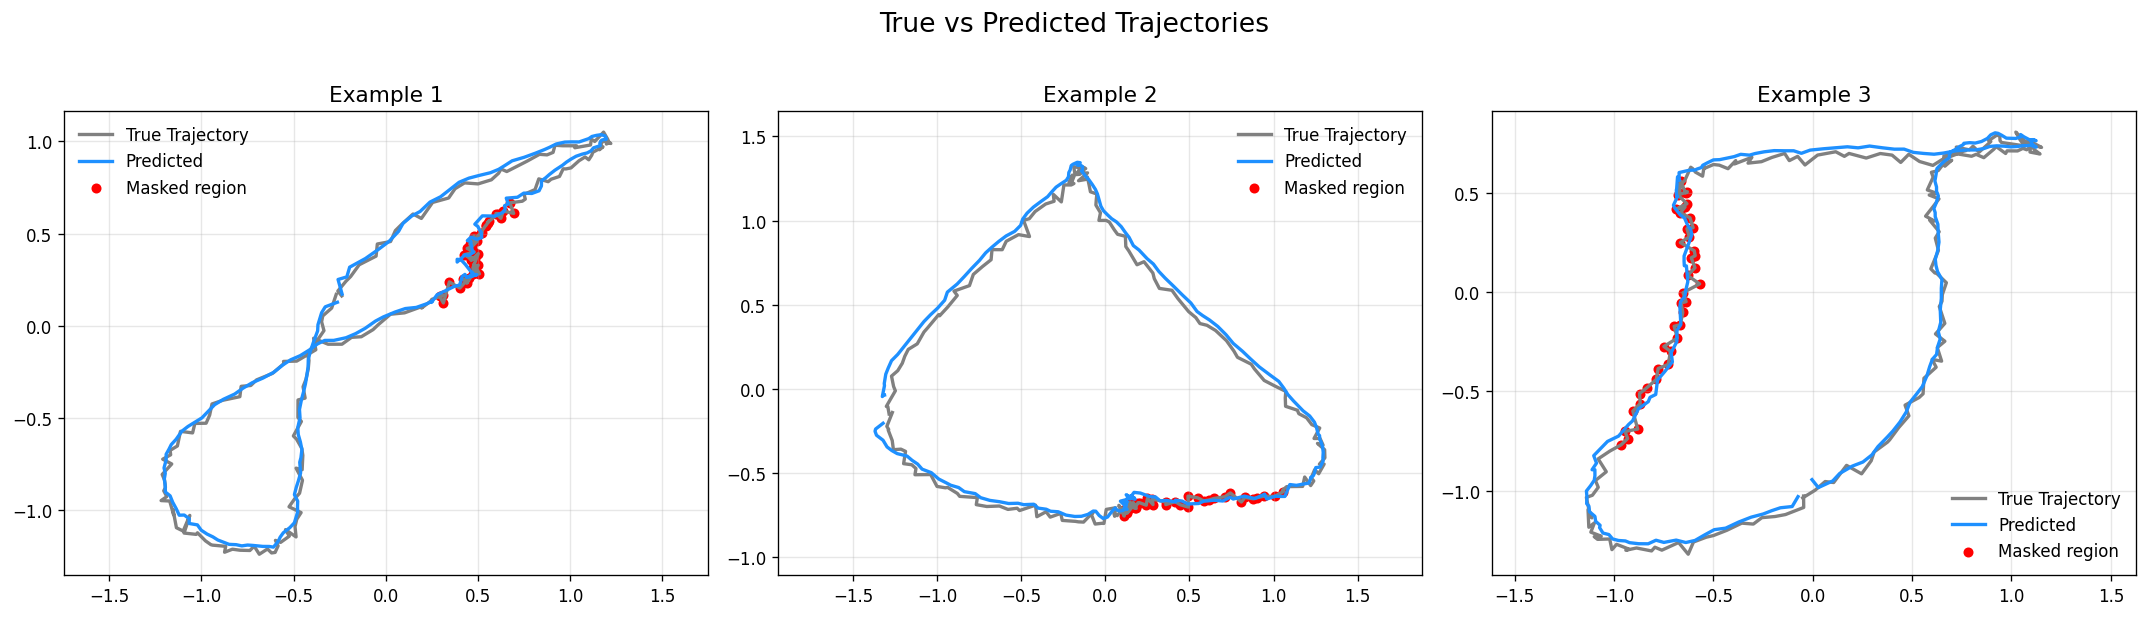

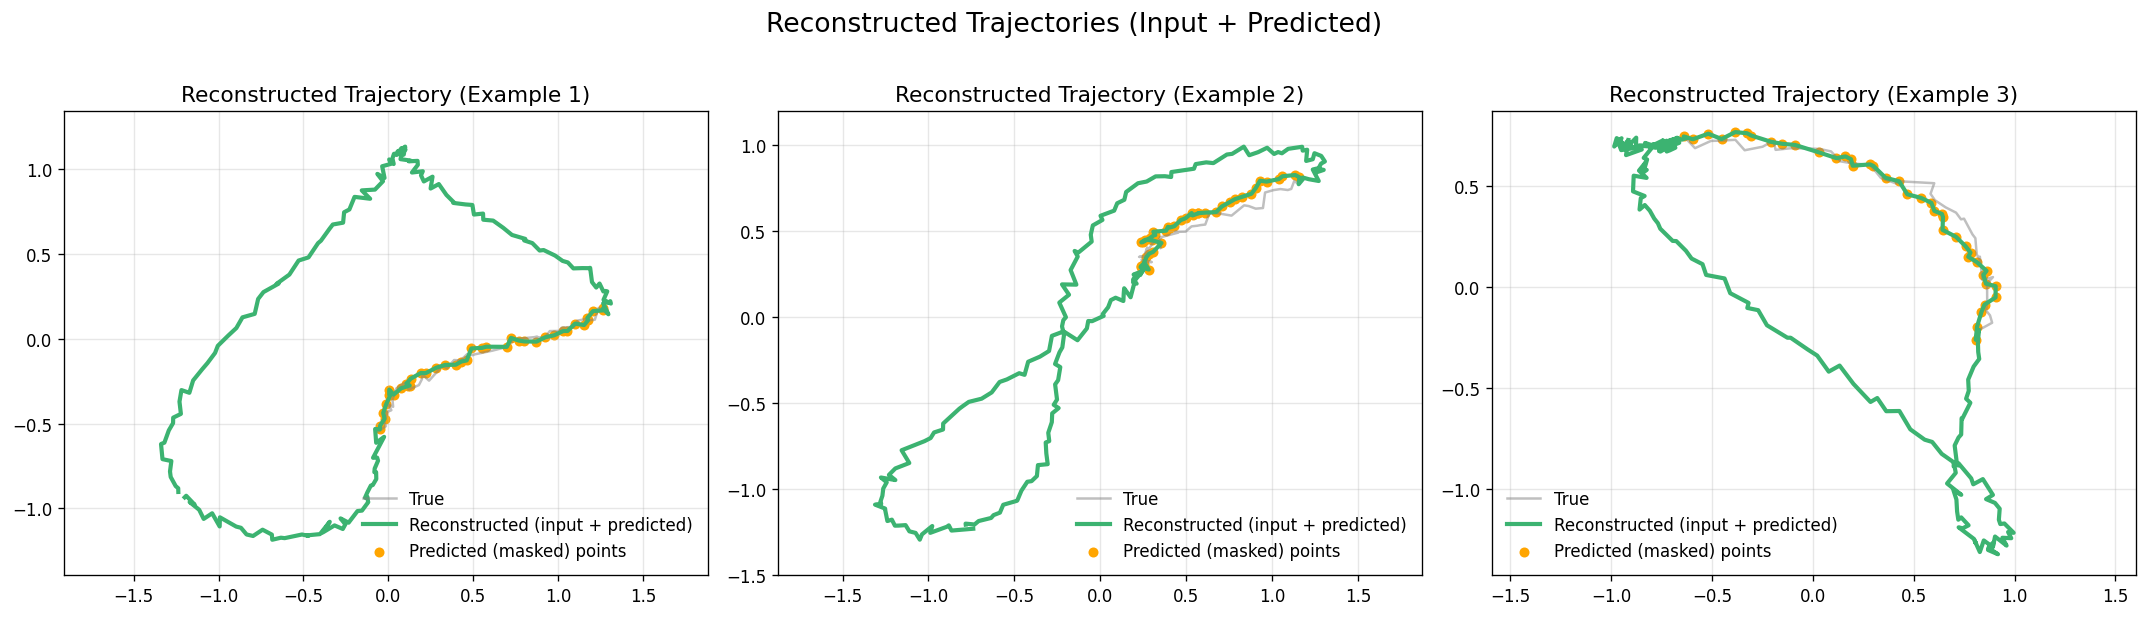

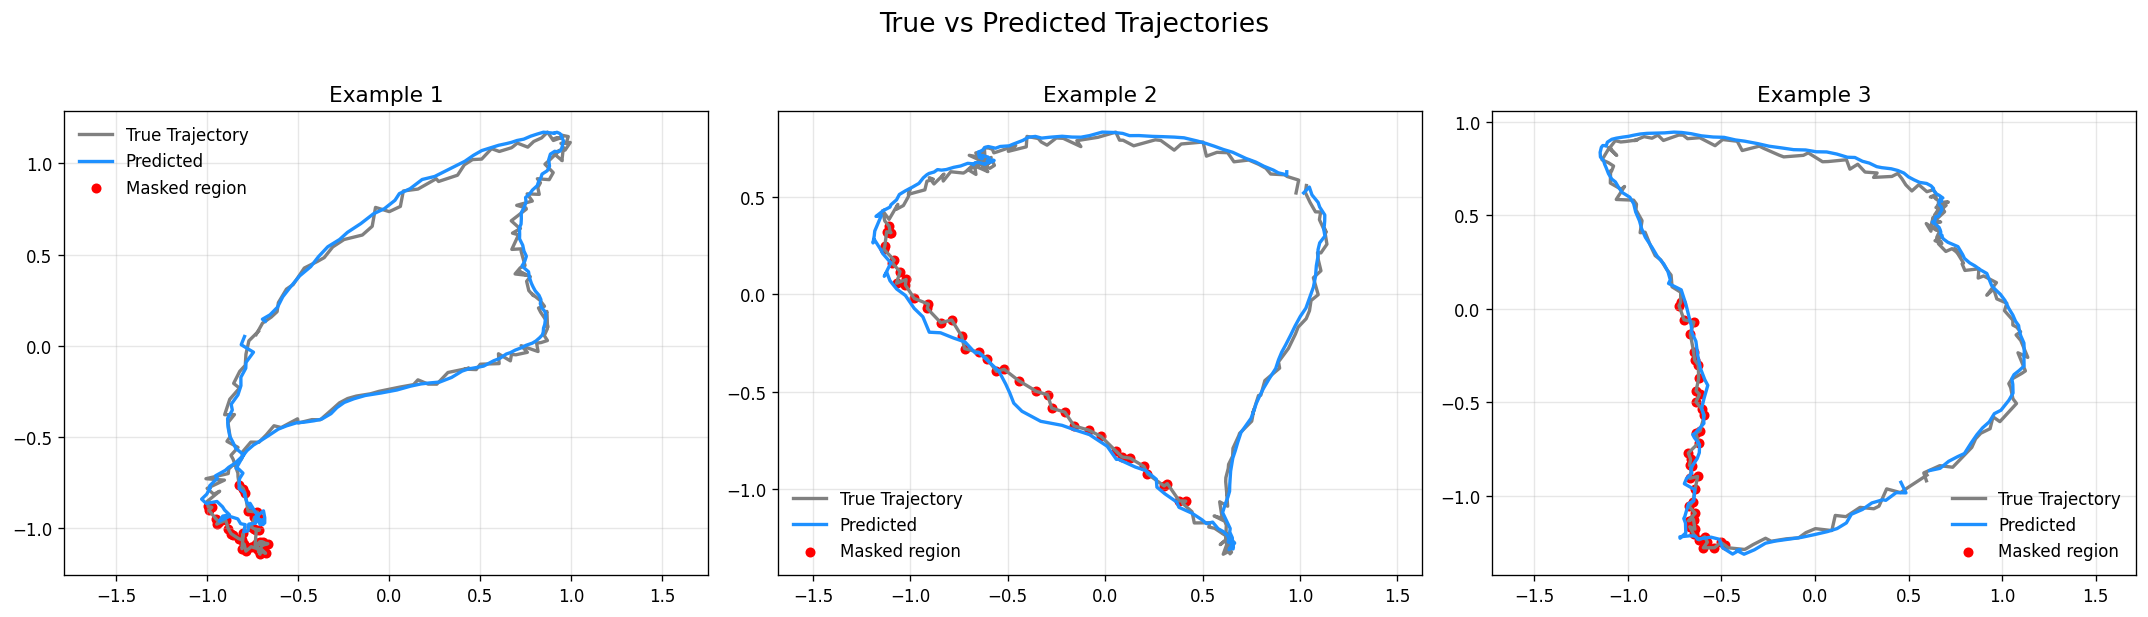

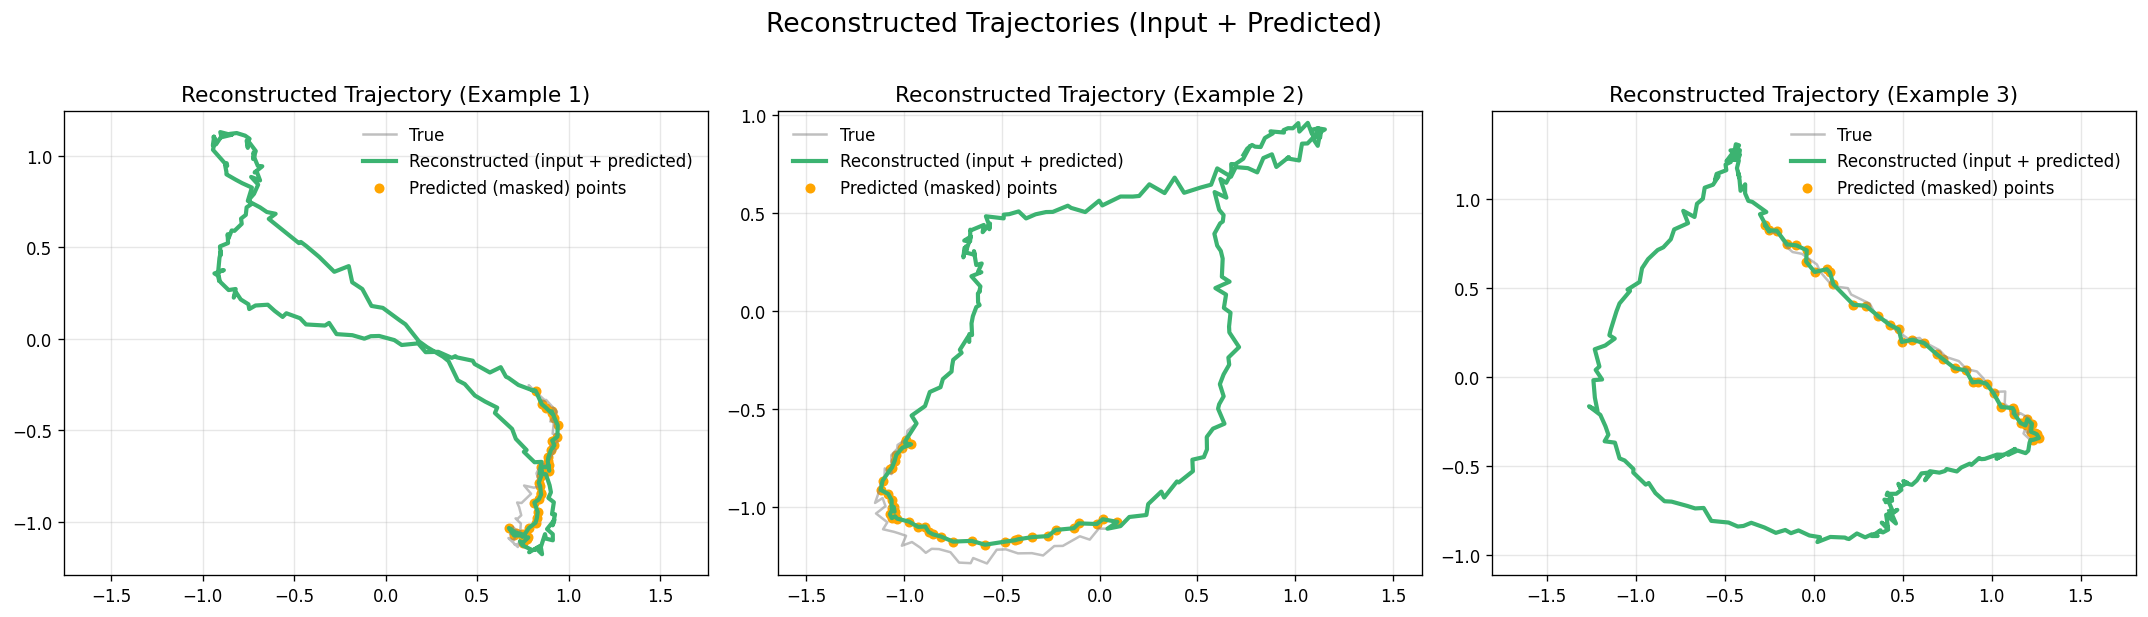

In [11]:

# ============================================================
# 6. Run everything
# ============================================================
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    num_train_samples = 1000
    num_val_samples = 200 # New: Number of validation samples
    num_test_samples = 300
    seq_len = 200

    # Adjusted total samples to accommodate validation set
    all_data, all_masks, t = create_dataset(num_samples=num_train_samples + num_val_samples + num_test_samples, seq_len=seq_len, mask_frac=0.2)

    # Splitting data into train, validation, and test sets
    data_train = all_data[:num_train_samples].copy()
    masks_train = all_masks[:num_train_samples].copy()

    data_val = all_data[num_train_samples : num_train_samples + num_val_samples].copy()
    masks_val = all_masks[num_train_samples : num_train_samples + num_val_samples].copy()

    data_test = all_data[num_train_samples + num_val_samples :].copy()
    masks_test = all_masks[num_train_samples + num_val_samples :].copy()

    model = TCN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=3e-3)

    train_losses, val_losses = train_tcn(model, optimizer, data_train, masks_train, data_val, masks_val, t, epochs=50, alpha=0.1, lambda_cont=0.5, lambda_smooth=0.5, device=device)
    evaluate_model(model, data_train, masks_train, t, device=device)
    evaluate_model(model, data_test, masks_test, t, device=device)
    visualize_results(model, data_train, masks_train, t, num_examples=3, device=device)
    visualize_results(model, data_test, masks_test, t, num_examples=3, device=device)


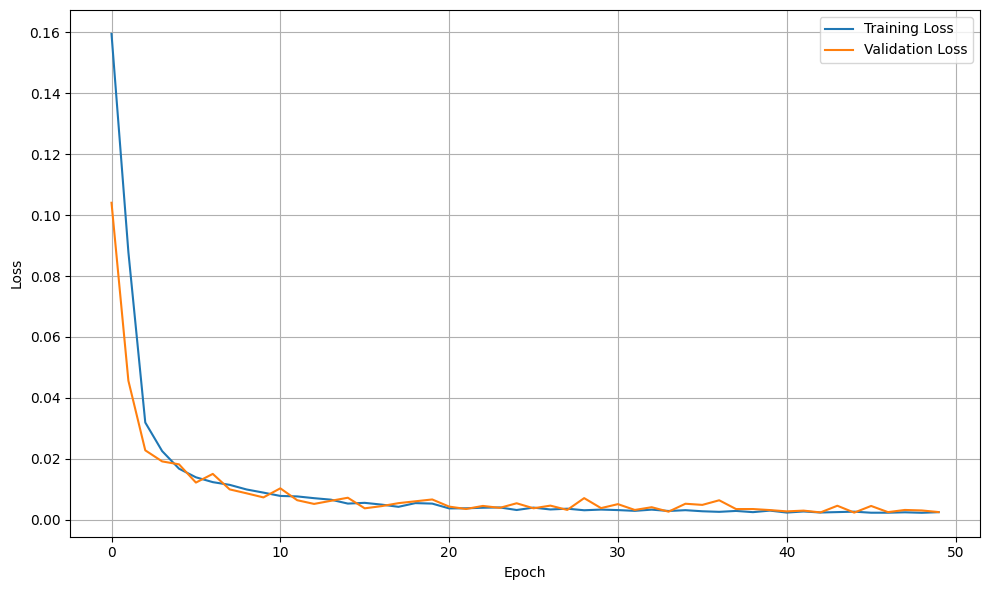

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('average_loss_train.pdf')
plt.show()